<a href="https://colab.research.google.com/github/finzawork-dev/ML_Algorithms/blob/main/PolynomialRegression(Class3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#import scikit as sk
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [5]:
df = pd.read_csv("/content/housing_cleaned-1.csv")

In [6]:
df
#analysing the data, we are using longitude and latitdes to make california mao through scatter plot

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
19659,-121.09,39.48,25.0,1665.0,374,845.0,330.0,1.5603,78100.0,INLAND
19660,-121.21,39.49,18.0,697.0,150,356.0,114.0,2.5568,77100.0,INLAND
19661,-121.22,39.43,17.0,2254.0,485,1007.0,433.0,1.7000,92300.0,INLAND
19662,-121.32,39.43,18.0,1860.0,409,741.0,349.0,1.8672,84700.0,INLAND


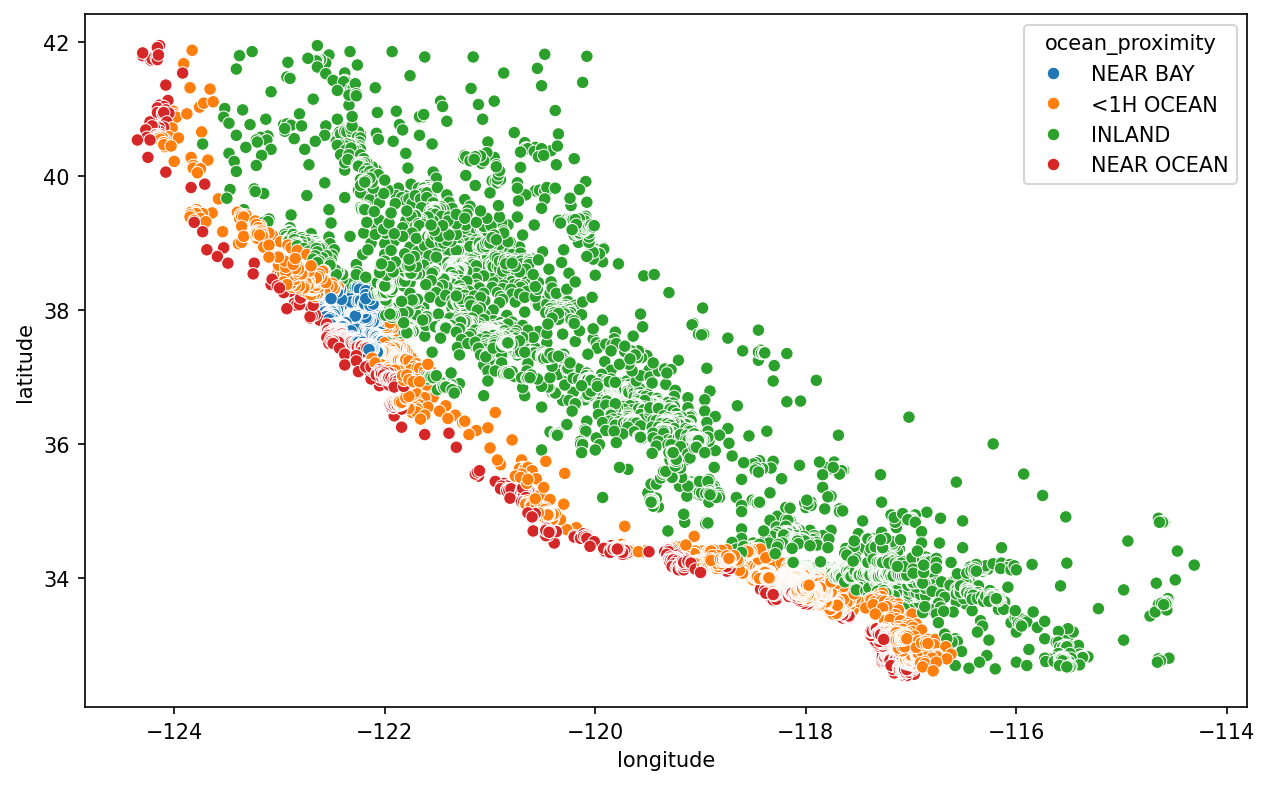

In [7]:
plt.figure(figsize=(10,6), dpi=150) #dpi refers to resolution
sns.scatterplot(x = 'longitude', y= 'latitude', data=df, hue='ocean_proximity')
#hue is a way to add third coordinate while keepig the plot 2D
plt.show()

In [8]:
#now we try to predict median income
X = df[['households', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'median_house_value']]
#we are not adding ocean proximity because it is a string and we cannot feed a ML algorithm a string val, can only do numeric
y= df[['median_income']]

In [9]:
train_rmse = []
test_rmse =[]

In [10]:
for d in range(1,6):
  model = PolynomialFeatures(degree = d)
  Extended_X = model.fit_transform(X)

  X_train, X_test, y_train, y_test = train_test_split(Extended_X, y, test_size=0.33, random_state=42)
  model = LinearRegression()
  model.fit(X_train, y_train)

  train_pred = model.predict(X_train)
  test_pred = model.predict(X_test)

  train_rmse.append(np.sqrt(mean_squared_error(y_train, train_pred)))
  test_rmse.append(np.sqrt(mean_squared_error(y_test, test_pred)))

In [13]:
test_pred

array([[2.94260217],
       [3.52123986],
       [2.90817333],
       ...,
       [4.0558117 ],
       [3.11758408],
       [3.74750196]])

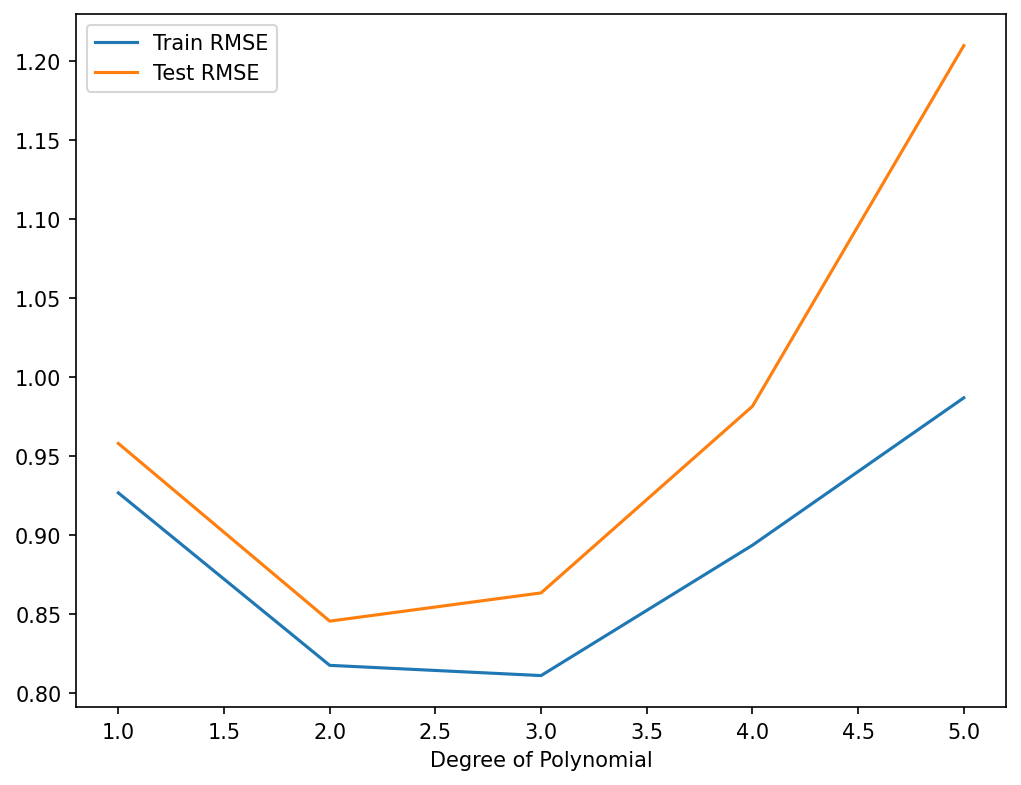

In [15]:
plt.figure(figsize=(8,6), dpi=150)
plt.plot(range(1,6), train_rmse[:9], label = 'Train RMSE')
plt.plot(range(1,6), test_rmse[:9], label = 'Test RMSE')
plt.xlabel('Degree of Polynomial')
plt.legend()

In [16]:
model = PolynomialFeatures(degree =3)
Extended_X = model.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(Extended_X, y, test_size=0.3, random_state=101)

my_model = LinearRegression()
my_model.fit(X_train, y_train)

y_hat = my_model.predict(X_test)

MAE = mean_absolute_error(y_test, y_hat)
RMSE = np.sqrt(mean_squared_error(y_test, y_hat))

In [17]:
MAE

0.6078351256594356

In [18]:
RMSE

np.float64(0.8465253345336379)